# Spotify Exploratory Data Analysis


# Data Loading

## Data Frame Creation, Track Popularity Transform,  and Variables Investigation

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
spotify_data = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv'
df = pd.read_csv(spotify_data)

## Initial Exploration

In [ ]:
df.shape

(32833, 23)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudne

In [ ]:
df.isnull().sum()

track_id                    0
track_name                  5
track_artist                5
track_popularity            0
track_album_id              0
track_album_name            5
track_album_release_date    0
playlist_name               0
playlist_id                 0
playlist_genre              0
playlist_subgenre           0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
dtype: int64

In [ ]:
df.nunique()

track_id                    28356
track_name                  23449
track_artist                10692
track_popularity              101
track_album_id              22545
track_album_name            19743
track_album_release_date     4530
playlist_name                 449
playlist_id                   471
playlist_genre                  6
playlist_subgenre              24
danceability                  822
energy                        952
key                            12
loudness                    10222
mode                            2
speechiness                  1270
acousticness                 3731
instrumentalness             4729
liveness                     1624
valence                      1362
tempo                       17684
duration_ms                 19785
dtype: int64

In [ ]:
df['track_popularity_shifted'] = np.where(df.track_popularity == 100, df.track_popularity - 0.1, df.track_popularity)
df['track_popularity_shifted'] = np.where(df.track_popularity == 0, df.track_popularity + 0.1, df.track_popularity_shifted)

df['track_popularity_fraction'] = df.track_popularity_shifted/100

df['track_popularity_transformed'] = np.log(df.track_popularity_fraction / (1 - df.track_popularity_fraction))

In [ ]:
df['track_popularity_transformed']

0        0.663294
1        0.708185
2        0.847298
3        0.405465
4        0.800119
           ...   
32828   -0.322773
32829   -1.386294
32830   -1.815290
32831   -1.734601
32832   -0.994623
Name: track_popularity_transformed, Length: 32833, dtype: float64

In [ ]:
df = df.drop(columns=['track_popularity', 'track_popularity_shifted', 'track_popularity_fraction'])

In [ ]:
df.groupby('track_id')['track_popularity_transformed'].nunique().value_counts()

track_popularity_transformed
1    28356
Name: count, dtype: int64

# Treatment of Variables

**Identifiers.**
track_id, track_album_id, playlist_id, playlist_name, and track_album_name are unique
identifiers or labels with no analytical and are excluded from
analysis. track_name and track_artist are kept only as readable labels for individual
data points, not as analysis variables.

**Numeric variables treated as categorical.**
mode and key are both stored as int64, but neither is really a continuous measurement.
mode is binary (0 = minor, 1 = major), and key represents one of 12 musical notes, so
both are treated as categorical variables for this analysis rather than continuous ones.

**Chosen variables.**
The selected variables are playlist_genre, mode, and key as categorical variables, and
valence, energy, and num_playlists as continuous variables, alongside the outcome
track_popularity_transformed.

playlist_genre is the primary stylistic categorization and a natural candidate for
explaining popularity differences across musical styles. playlist_subgenre is held back
for a more granular categorical to categorical comparison later, rather than the base
summary statistics.

mode (major/minor) and valence (a continuous positivity score) both get at musical
"mood," so pairing them lets us compare a categorical and continuous measure of a
similar concept. key was kept to test whether certain musical keys line up with certain
genres or popularity trends, pairing naturally with playlist_genre.

energy was kept as a broad audio feature measure with a plausible link to popularity,
while loudness and tempo were dropped. loudness looked likely to overlap with energy,
and tempo had too much granularity (17,684 unique values) to be useful without binning.

num_playlists is an engineered variable counting how many distinct playlists a track
appears in. It tests whether broader playlist placement on its own is associated with
higher popularity.

**Duplicates.**
Songs can appear in multiple playlists, which creates duplicate rows by track_id. I
confirmed track_popularity stays constant within each track_id group, so the duplication
doesn't distort the outcome variable. I chose to keep the duplicate rows instead of
deduplicating, since playlist appearance count is itself something worth looking at.
Readers should note that genre based charts reflect playlist-genre entries, not strictly
unique songs.

#  Summary Statistics


In [ ]:
df['num_playlists'] = df.groupby('track_id')['playlist_id'].transform('nunique')

In [ ]:
df['playlist_genre'].value_counts()

playlist_genre
edm      6043
rap      5746
pop      5507
r&b      5431
latin    5155
rock     4951
Name: count, dtype: int64

In [ ]:
df['mode'].value_counts()

mode
1    18574
0    14259
Name: count, dtype: int64

In [ ]:
df['key'].value_counts()

key
1     4010
0     3454
7     3352
9     3027
11    2996
2     2827
5     2680
6     2670
8     2430
10    2273
4     2201
3      913
Name: count, dtype: int64

In [ ]:
df[['valence', 'energy', 'num_playlists', 'track_popularity_transformed']].describe()


,valence,energy,num_playlists,track_popularity_transformed
count,32833.000000,32833.000000,32833.000000,32833.000000
mean,0.510561,0.698619,1.356044,-0.827397
std,0.233146,0.180910,0.860129,2.212342
min,0.000000,0.000175,1.000000,-6.906755
25%,0.331000,0.581000,1.000000,-1.152680
50%,0.512000,0.721000,1.000000,-0.200671
75%,0.693000,0.840000,1.000000,0.489548
max,0.991000,1.000000,8.000000,6.906755


# Analyzing The Chosen Variables

## Marginal Distributions of Categorical Data

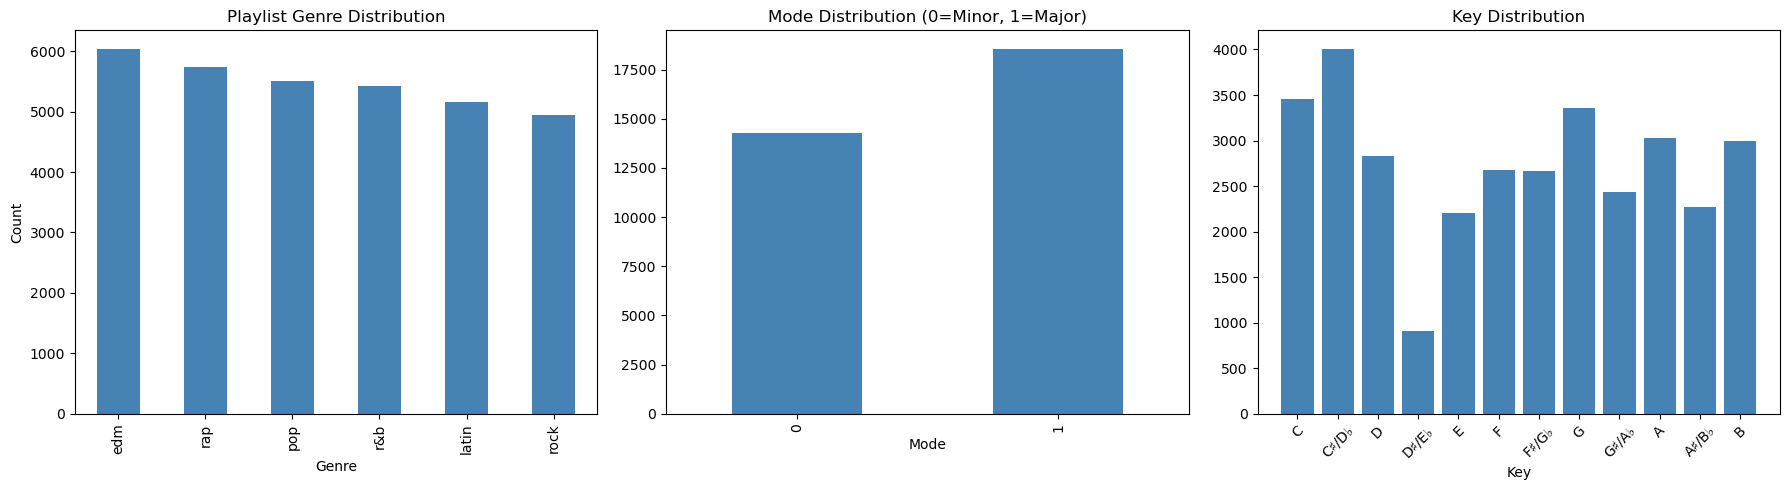

In [ ]:
key_labels = ['C', 'C♯/D♭', 'D', 'D♯/E♭', 'E', 'F', 'F♯/G♭', 'G', 'G♯/A♭', 'A', 'A♯/B♭', 'B']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df['playlist_genre'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Playlist Genre Distribution')
axes[0].set_xlabel('Genre')
axes[0].set_ylabel('Count')
df['mode'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Mode Distribution (0=Minor, 1=Major)')
axes[1].set_xlabel('Mode')
key_counts = df['key'].value_counts().sort_index()
axes[2].bar(key_counts.index, key_counts.values, color='steelblue')
axes[2].set_title('Key Distribution')
axes[2].set_xlabel('Key')
axes[2].set_xticks(range(12))
axes[2].set_xticklabels(key_labels, rotation=45)
plt.tight_layout()
plt.show()

Genre counts are fairly balanced across all six categories, with edm slightly the highest and rock slightly the lowest. Mode skews toward major, with more major tracks than minor. Key is spread across all 12 notes, with C♯/D♭ the most common and D♯/E♭ noticeably the least common of the twelve.

## Marginal Distribution of Continuous Data

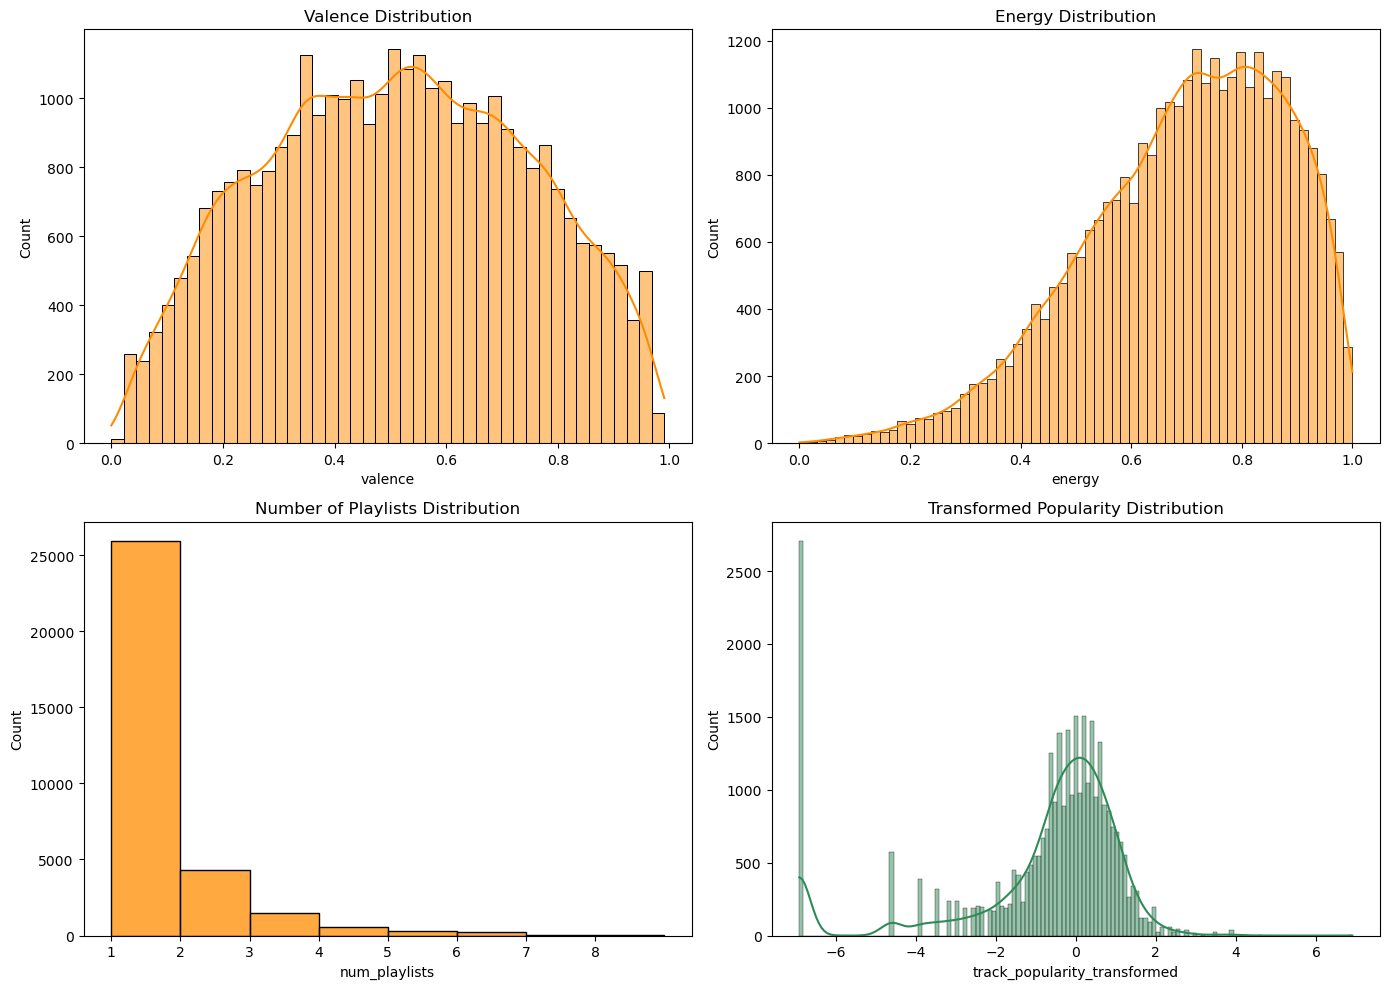

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(df['valence'], kde=True, ax=axes[0,0], color='darkorange')
axes[0,0].set_title('Valence Distribution')
sns.histplot(df['energy'], kde=True, ax=axes[0,1], color='darkorange')
axes[0,1].set_title('Energy Distribution')
sns.histplot(df['num_playlists'], bins=range(1,10), ax=axes[1,0], color='darkorange')
axes[1,0].set_title('Number of Playlists Distribution')
axes[1,0].set_xticks(range(1,9))
sns.histplot(df['track_popularity_transformed'], kde=True, ax=axes[1,1], color='seagreen')
axes[1,1].set_title('Transformed Popularity Distribution')
plt.tight_layout()
plt.show()

Num_playlists is skewed toward low counts, most songs sit at just a few playlist appearances, with a small number reaching the max of 8. Track_popularity_transformed comes out roughly symmetric after the logit transform, ranging from about -6.9 to 6.9, which is what we'd expect given the shift applied to the original 0 and 100 edge cases before transforming.

## Categorical vs Categorical Comparison: Playlist Genre vs Mode

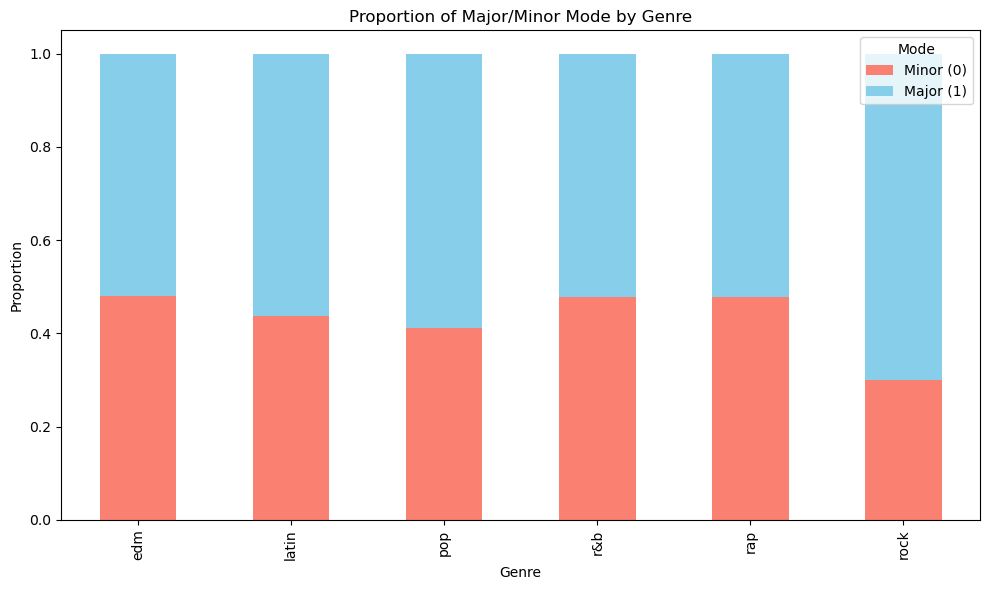

In [ ]:
crosstab = pd.crosstab(df['playlist_genre'], df['mode'], normalize='index')
crosstab.plot(kind='bar', stacked=True, figsize=(10,6), color=['salmon','skyblue'])
plt.title('Proportion of Major/Minor Mode by Genre')
plt.xlabel('Genre')
plt.ylabel('Proportion')
plt.legend(['Minor (0)', 'Major (1)'], title='Mode')
plt.tight_layout()
plt.show()

Rock leans major the most out of any genre, around 70%. R&b, rap, and edm sit closer to an even 50/50 split. Pop and latin lean slightly more minor, sitting a bit below 50%.

## Categorical vs Continuous Comparison: Playlist Genre vs Track Popularity (Transformed)

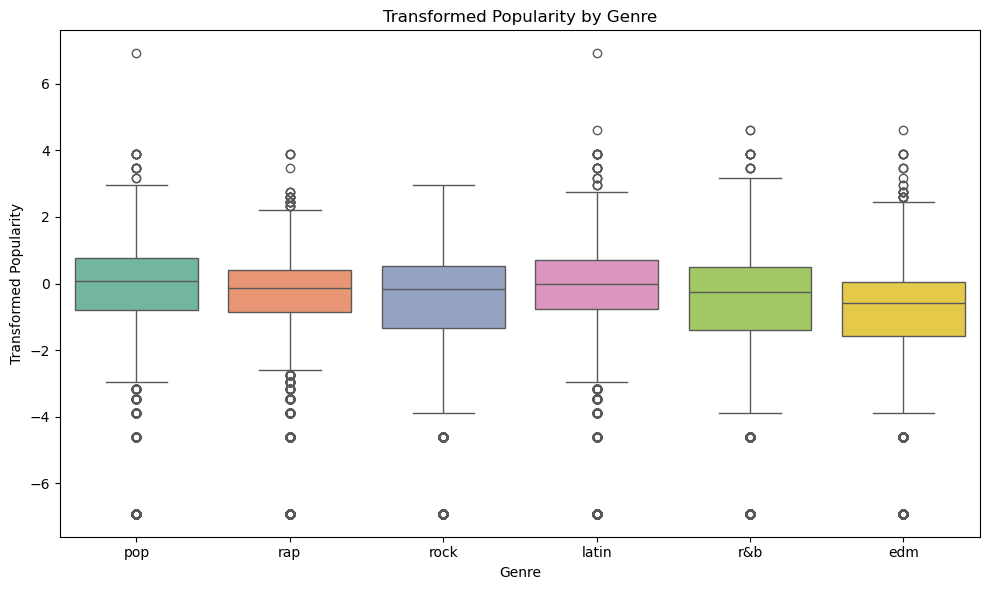

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='playlist_genre', y='track_popularity_transformed', hue='playlist_genre', palette='Set2', legend=False)
plt.title('Transformed Popularity by Genre')
plt.xlabel('Genre')
plt.ylabel('Transformed Popularity')
plt.tight_layout()
plt.show()

Medians are roughly similar across all genres, so genre alone doesn't clearly separate high and low popularity tracks. Rock stands out as the only genre without any outliers above the top whisker, suggesting it may not produce the same kind of viral outlier hits other genres do.

## Categorical vs Continuous: Mode vs Track Popularity (Transformed)

1.   List item
2.   List item



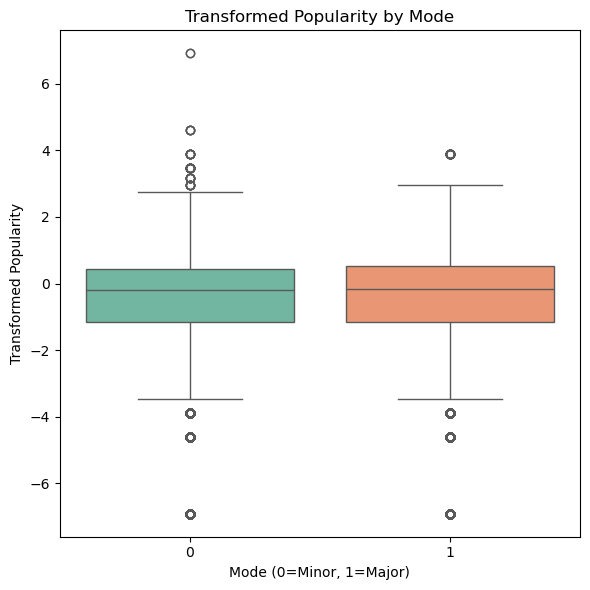

In [ ]:
plt.figure(figsize=(6,6))
sns.boxplot(data=df, x='mode', y='track_popularity_transformed', hue='mode', palette='Set2', legend=False)
plt.title('Transformed Popularity by Mode')
plt.xlabel('Mode (0=Minor, 1=Major)')
plt.ylabel('Transformed Popularity')
plt.tight_layout()
plt.show()

Major and minor tracks show very similar popularity distributions here, with no clear separation between the two. This lines up with what we see later once mode is broken out by genre as well.

## Continuous vs Continuous: Energy vs Valence

---



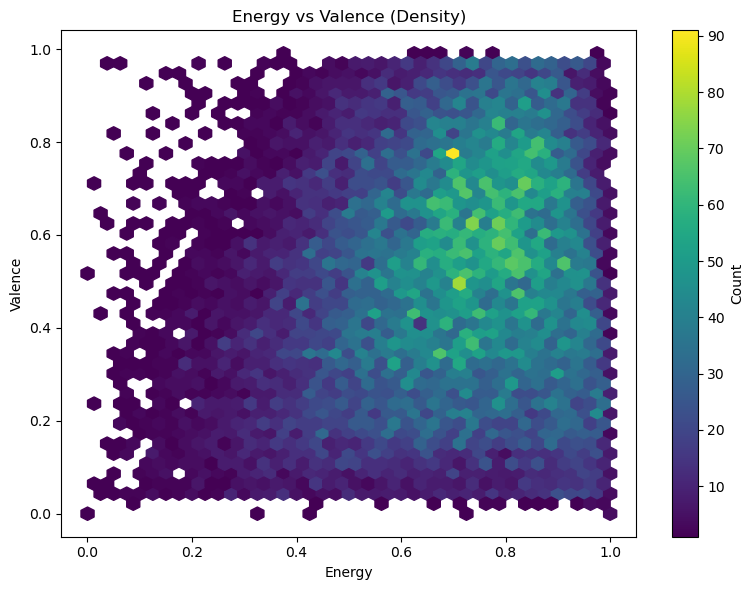

In [ ]:
plt.figure(figsize=(8,6))
plt.hexbin(df['energy'], df['valence'], gridsize=40, cmap='viridis', mincnt=1)
plt.colorbar(label='Count')
plt.xlabel('Energy')
plt.ylabel('Valence')
plt.title('Energy vs Valence (Density)')
plt.tight_layout()
plt.show()

Switching to a hexbin was necessary here since a regular scatterplot was unreadable at this row count. The density view makes the actual concentration of songs across energy and valence visible instead of one solid overplotted mass.

## Continuous vs Continuous: Num Playlists vs Track Popularity (Transformed)

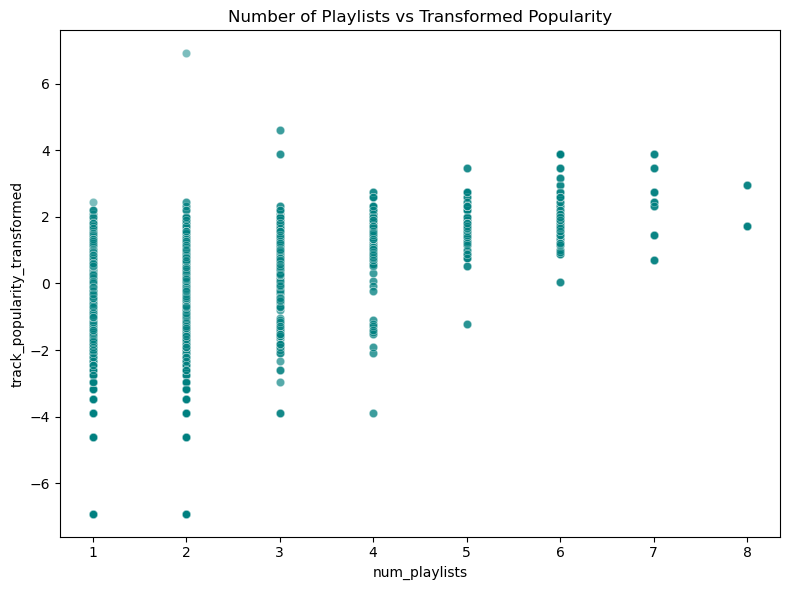

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='num_playlists', y='track_popularity_transformed', alpha=0.3, color='teal')
plt.title('Number of Playlists vs Transformed Popularity')
plt.tight_layout()
plt.show()

There's a slow, log-like rise, popularity increases with playlist count early on, then levels off. The most popular songs aren't sitting at the max playlist count of 8, so playlist reach looks more like a popularity floor than something that drives the very top performers.

## Continuous vs Continuous: Energy vs Track Popularity (Transformed)

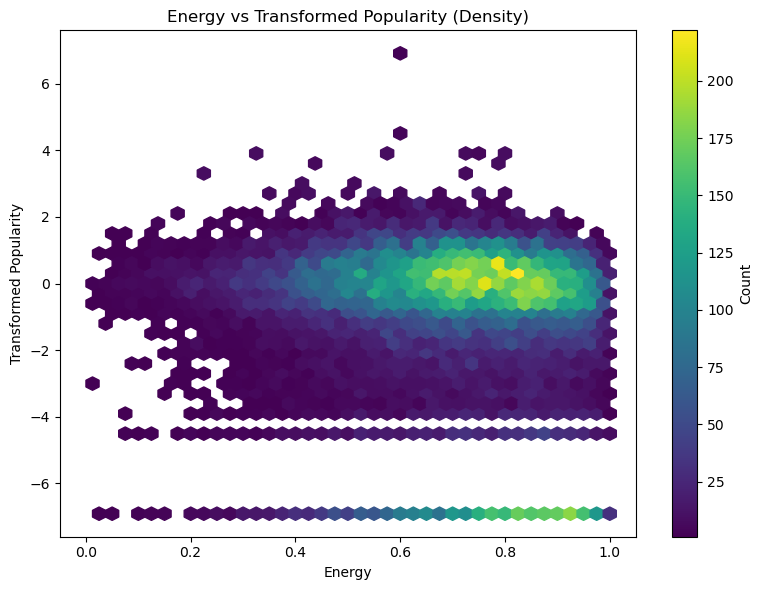

In [ ]:
plt.figure(figsize=(8,6))
plt.hexbin(df['energy'], df['track_popularity_transformed'], gridsize=40, cmap='viridis', mincnt=1)
plt.colorbar(label='Count')
plt.xlabel('Energy')
plt.ylabel('Transformed Popularity')
plt.title('Energy vs Transformed Popularity (Density)')
plt.tight_layout()
plt.show()

The highest-popularity songs are spread across the whole energy range, not clustered at one end. The densest area of the plot sits around 0.8 energy but near zero transformed popularity, so that hotspot reflects where most songs sit overall, not where the most popular songs sit.

# Grouped Relationships  
**The following comparisons break relationships out by genre or mode to check whether patterns seen above hold consistently across groups, or shift depending on category.**

## Energy vs Track Popularity Transformed, coloured by Playlist Genre

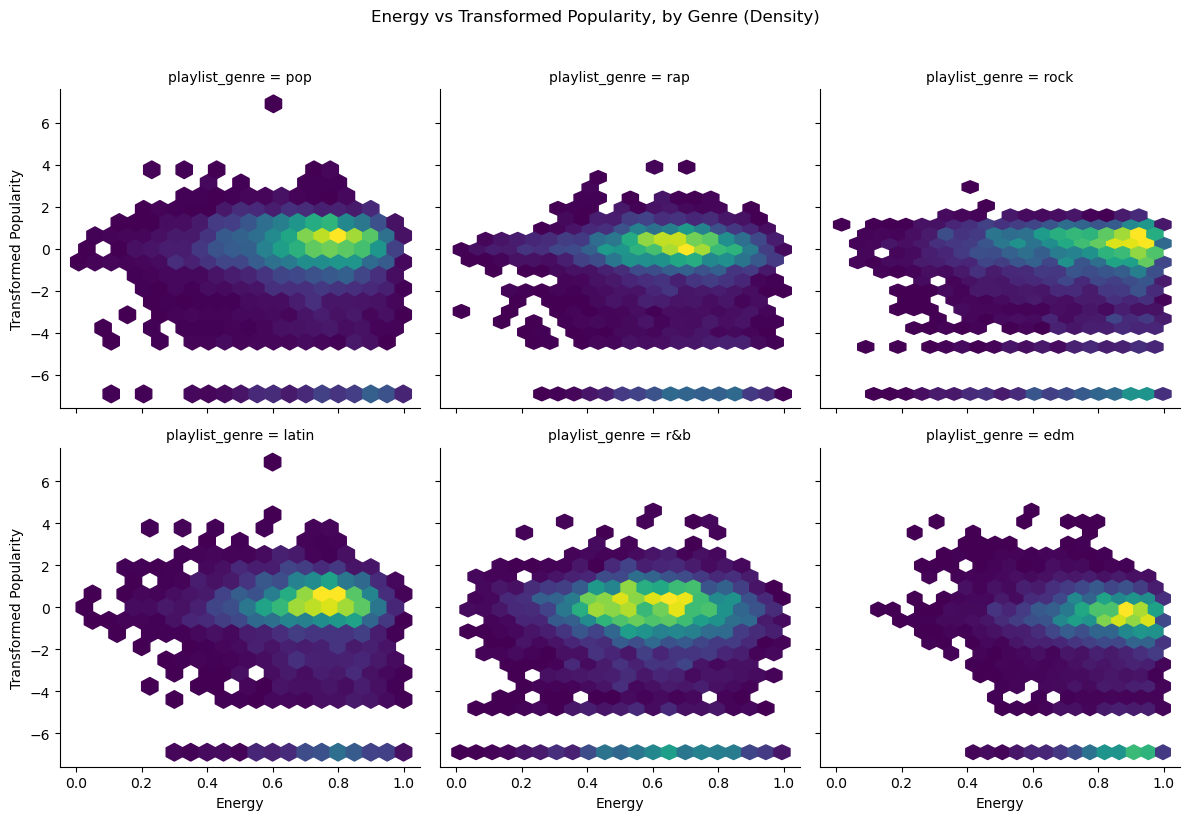

In [ ]:
g = sns.FacetGrid(df, col='playlist_genre', col_wrap=3, height=4)
g.map_dataframe(lambda data, color: plt.hexbin(data['energy'], data['track_popularity_transformed'], gridsize=20, cmap='viridis', mincnt=1))
g.set_axis_labels('Energy', 'Transformed Popularity')
g.fig.suptitle('Energy vs Transformed Popularity, by Genre (Density)', y=1.02)
plt.tight_layout()
plt.show()

Each genre has its own distinct energy hotspot rather than sharing one common pattern. Edm and rock cluster around 0.8-1.0 energy, latin and pop cluster around 0.8, while rap and r&b are more spread out across 0.4-0.8. As with the ungrouped version, these hotspots mark where most songs sit, not necessarily where the most popular songs sit.

## Valence vs Track Popularity (Transformed), coloured by Mode

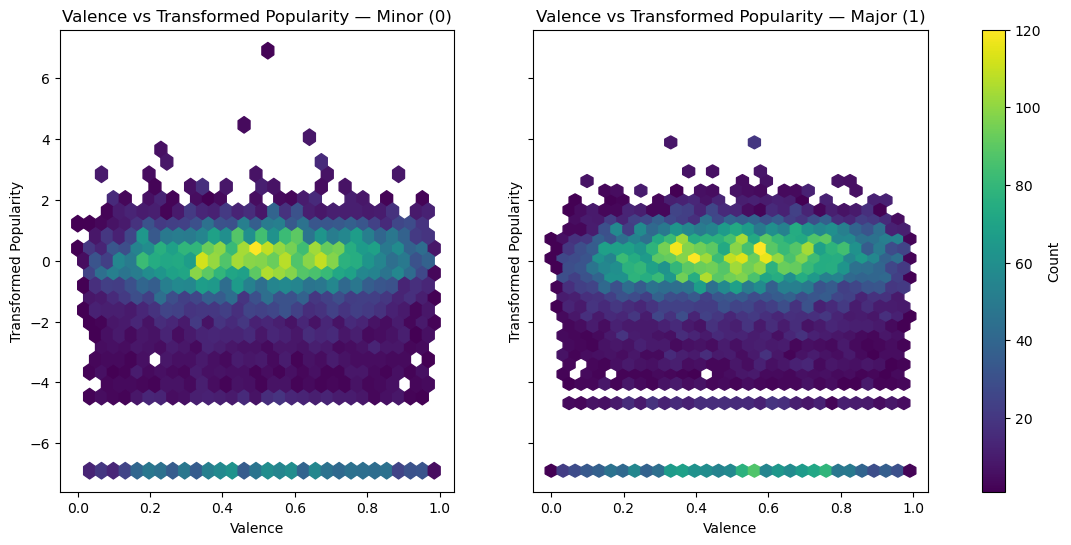

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,6), sharex=True, sharey=True)

for ax, m, label in zip(axes, [0, 1], ['Minor (0)', 'Major (1)']):
    subset = df[df['mode'] == m]
    hb = ax.hexbin(subset['valence'], subset['track_popularity_transformed'], gridsize=30, cmap='viridis', mincnt=1)
    ax.set_title(f'Valence vs Transformed Popularity — {label}')
    ax.set_xlabel('Valence')
    ax.set_ylabel('Transformed Popularity')

fig.colorbar(hb, ax=axes, label='Count')
plt.show()

Minor tracks skew slightly toward higher valence density, around 0.6, while major tracks skew slightly lower, around 0.4, which runs against the usual assumption that major key means happier sounding. Neither mode shows a clear valence range tied to higher popularity, and there are too few high-popularity points to draw a strong conclusion either way.

## Energy Distribution by Genre

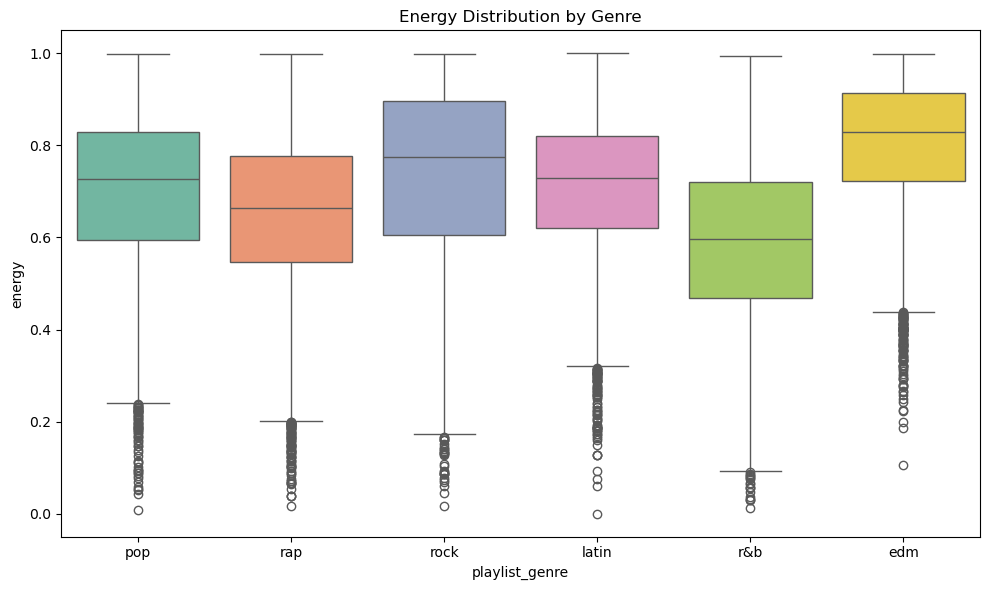

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='playlist_genre', y='energy', hue='playlist_genre', palette='Set2', legend=False)
plt.title('Energy Distribution by Genre')
plt.tight_layout()
plt.show()

Median energy sits between about 0.6 and 0.8 across genres. Every genre shows a large cluster of outliers below the bottom whisker, meaning most genres contain a meaningful chunk of unusually low-energy tracks even where you wouldn't expect it.

## Track Popularity (Transformed) by Genre split by Mode

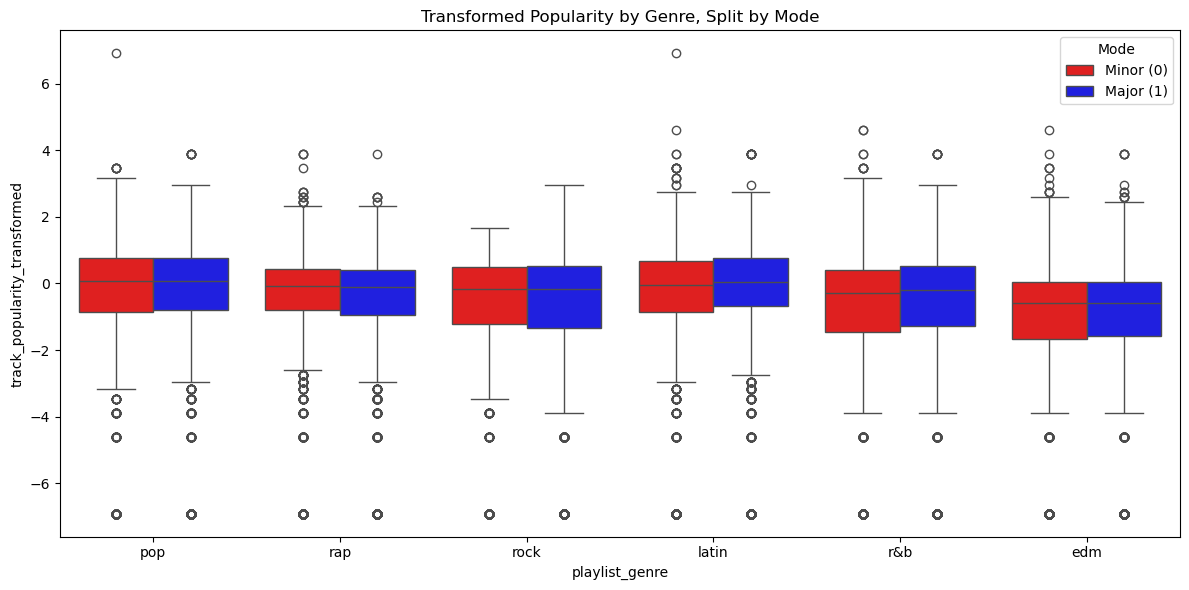

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='playlist_genre', y='track_popularity_transformed', hue='mode', palette={0:'red', 1:'blue'})
plt.title('Transformed Popularity by Genre, Split by Mode')
handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles, ['Minor (0)', 'Major (1)'], title='Mode')
plt.tight_layout()
plt.show()

Major and minor distributions look nearly identical within every genre, with no clear sign that mode shifts popularity one way or the other once genre is accounted for.

## Findings and Discussion

Overall, no single variable gave a clean, obvious relationship with track popularity.
Popular songs were spread out across the range for energy and valence, not stacked up
at one end. So on their own, these audio features probably aren't strong predictors.
A model will likely need to combine several features together, or lean more on genre,
rather than expect one variable to carry the prediction.

A few things are still worth carrying forward into modeling:

Num_playlists had the clearest pattern out of everything looked at. Popularity rises
with playlist count at first, then levels off, kind of like log growth. Interestingly,
the most popular songs weren't sitting at the max playlist count of 8, so playlist reach
looks more like it sets a popularity floor than it drives the very top performers.

Playlist_genre showed real differences in style, even if not in popularity directly.
Energy hotspots were different by genre, EDM and rock clustered around 0.8-1.0 energy,
while rap and R&B were more spread out across 0.4-0.8. Genres also split differently on
mode, rock leaned major about 70% of the time, while pop and latin were closer to 40%.
But median popularity was about the same across genres, so genre seems to explain the
sound of a song more than how popular it gets.

Mode showed a small, kind of odd pattern with valence. Minor key songs skewed slightly
higher in valence (around 0.6) and major key songs skewed slightly lower (around 0.4),
which goes against the usual assumption that major key means happier. That said, mode
barely moved the needle on popularity itself, overall or within any genre, so this seems
more like an interesting quirk than something useful for prediction.

The hexbin plots were the most useful visualizations here. Regular scatterplots stopped
being readable once we hit this many rows (32,833), and switching to density plots is
what actually let us see that the densest area of energy vs popularity sat near zero,
not at either popularity extreme. The same fix mattered again for valence and for
energy split by genre, where a single combined scatterplot was hiding genre-specific
clustering that only showed up once each genre got its own panel.

The boxplots split by mode within each genre were useful in a different way, they
showed that mode basically doesn't matter for popularity, and a confident "no" is still
a useful finding heading into modeling.

A couple other things worth noting. Energy by genre had a big pile of outliers below
the bottom whisker in every single genre, so most genres have a chunk of unusually
low energy tracks even if that's not what you'd expect from the genre. Rock was also
the only genre with no outliers above the top whisker on popularity, so it might not
have the same kind of viral hits that other genres get.

The duplicate playlist rows ended up being useful instead of a problem. Turning that
into num_playlists provided the clearest signal in the whole dataset, so keeping the
duplicates instead of dropping them was the right call.